# Typography

Text stays live characters: styled ranges, per-glyph moves and rotations, outlines and cut-outs, and lines
in Hindi, Bengali, Urdu, Japanese and Chinese.

Run it as ``python typography.py`` or open ``typography.ipynb`` to see each step.

In [1]:
import math

import svgwriter as svg

Text stays text. Slicing a `Text` selects a character range that can be wrapped in a styled `<tspan>`.

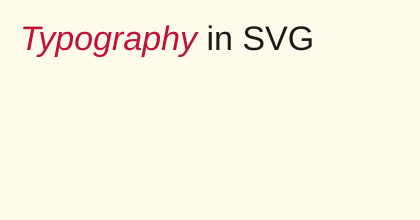

In [2]:
WIDTH, HEIGHT = 420, 220
SERIF = "Georgia, Times New Roman, serif"
SANS = "Arial, Helvetica, sans-serif"

doc = svg.Document(WIDTH, HEIGHT)
doc.style("text { font-family: Arial, Helvetica, sans-serif; } .accent { fill: #be123c; }")
doc.rect(0, 0, WIDTH, HEIGHT, fill="#fffbeb")

title = doc.text("Typography in SVG", x=20, y=50, font_size=34, font_family=SERIF, fill="#1c1917")
title[0:10].wrap(class_="accent", font_style="italic")
doc

Iterating a `Text` yields its characters, so each can move on its own; a slice rotates as a group.

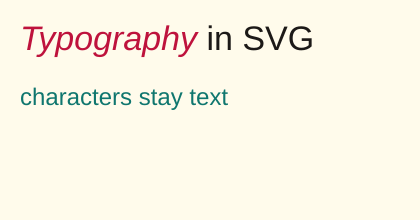

In [3]:
wave = doc.text("characters stay text", x=20, y=105, font_size=24, fill="#0f766e")
for index, glyph in enumerate(wave):
    glyph.translate(0, 6 * math.sin(index / 2))
wave[0:10].rotate(-8)
doc

Subtracting text from a shape cuts the letters out of it, as a stencil.

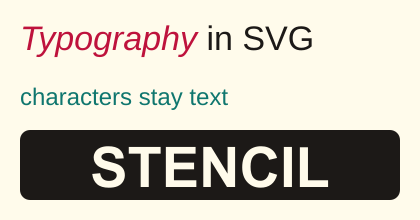

In [4]:
stencil = svg.rect(20, 130, 380, 70, rx=10) - svg.text("STENCIL", x=210, y=187, font_size=56,
                                                      font_family=SANS, font_weight="bold",
                                                      text_anchor="middle")
doc += stencil.update(fill="#1c1917")
doc

`glyphs()` converts text to one outline path per character, which then scale like any shape.

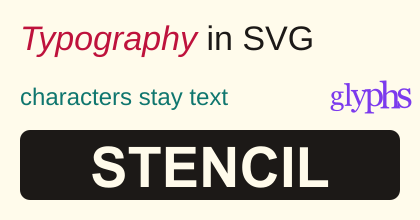

In [5]:
outlines = svg.text("glyphs", x=330, y=105, font_size=28, font_family=SERIF).glyphs()
for index, path in enumerate(outlines):
    path.update(fill="#7c3aed").scale(1 + index * 0.08)
doc += outlines
doc

## World scripts

Scripts that need shaping (Devanagari, Bengali, Arabic) and CJK text work with any `font_family`: where the
font has no glyph, layout falls back per character to an installed font that has one. `xml_lang` steers
the choice for shared CJK characters, and `direction="rtl"` sets Urdu from the right: its start is the
right end, so `x` is where the line begins.

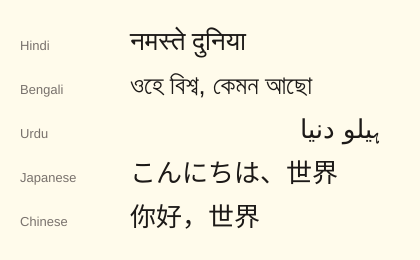

In [6]:
LINES = (
    ("Hindi", "नमस्ते दुनिया", {}),
    ("Bengali", "ওহে বিশ্ব, কেমন আছো", {}),
    ("Urdu", "ہیلو دنیا", {"direction": "rtl", "x": 380}),
    ("Japanese", "こんにちは、世界", {"xml_lang": "ja"}),
    ("Chinese", "你好，世界", {"xml_lang": "zh"}),
)
world = svg.Document(WIDTH, 40 + 44 * len(LINES))
world.rect(0, 0, WIDTH, 40 + 44 * len(LINES), fill="#fffbeb")
for row, (name, line, options) in enumerate(LINES):
    baseline = 50 + 44 * row
    world.text(name, x=20, y=baseline, font_size=13, font_family=SANS, fill="#78716c")
    options = {"x": 130, **options}
    world.text(line, y=baseline, font_size=26, font_family=SANS, fill="#1c1917", **options)
world

## Typefaces

A `Typeface` is a font family of faces. Text set in it gets the face that CSS font matching picks for its
weight, `measure` gives shaped widths for laying words out, and each face reports its metrics: here the
baseline, x-height and cap height of the bold face.

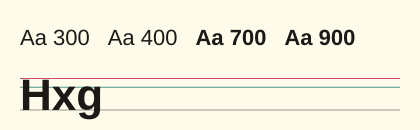

In [7]:
sans = svg.Typeface("sans-serif")
faces = svg.Document(WIDTH, 130)
faces.rect(0, 0, WIDTH, 130, fill="#fffbeb")
x = 20
for weight in (300, 400, 700, 900):
    label = f"Aa {weight}"
    faces.text(label, x=x, y=45, font_family=sans, font_size=22, font_weight=weight, fill="#1c1917")
    x += sans.measure(label, 22, weight=weight) + 18
metrics = sans.face(weight=700).metrics.at(44)
for height, color in ((0, "#78716c"), (metrics.x_height, "#0f766e"), (metrics.cap_height, "#be123c")):
    faces.line(20, 110 - height, 400, 110 - height, stroke=color, stroke_width=0.75)
faces.text("Hxg", x=20, y=110, font_family=sans, font_size=44, font_weight=700, fill="#1c1917")
faces

Save SVG and a 2x PNG.

In [8]:
doc.save("04_typography.svg")
doc.save("04_typography.png", scale=2)
world.save("04_scripts.svg")
faces.save("04_typefaces.svg")